# Validation: batched grid pipeline and mode summation

Companion to `tests/test_jax_pipeline.py`; sections **assert** their
checks. The batched circular-grid pipeline is compared field-by-field
against the CPU grid generator, the spheroidal→spherical projection
against `cast_to_spherical`, and the summation einsums against direct
loops.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from hblteuk.geo import MiniGeo
from hblteuk import collocode
from hblteuk.mode import TeukolskyPointParticleModeGridGenerator
from hblteuk.swsh import SpinWeightedSpheroidalHarmonic
from hblteuk.jax import (solve_circular_grid, project_to_spherical,
                         evaluate_multidomain, swsh_theta_values,
                         assemble_field)

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
orbit = MiniGeo(0.9, 10.0, 0.0, 1.0)
lmax = 5
solver = collocode.CollocationODEFixedMultiDomainFixedStepSolver(n=32)
gen = TeukolskyPointParticleModeGridGenerator(
    orbit, solver=solver,
    solver_kwargs={"subdomains": 150, "tol": 1e-13, "spacing": "arcsinh7"})
gen.optimize(-2, lmax)
cpu = gen(-2, [2, lmax])
jx = solve_circular_grid(orbit, -2, [2, lmax], gen)
print(f"{cpu.mode_num} modes solved on both paths")

32 modes solved on both paths


## 1. Grid parity, mode by mode

Amplitudes, eigenvalues, coupling, and evaluated radial solutions against
the CPU grid generator. The static $m = 0$ column agrees identically (same
code path); radiative modes agree to solver roundoff.

worst radiative amplitude diff: 2.3e-09


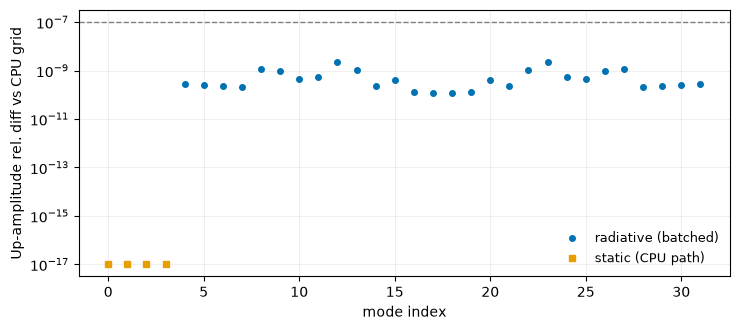

In [2]:
rel_amp = np.abs(jx.amplitudes["Up"] - cpu.amplitudes["Up"]) \
    / np.abs(cpu.amplitudes["Up"])
rel_amp_in = np.abs(jx.amplitudes["In"] - cpu.amplitudes["In"]) \
    / np.abs(cpu.amplitudes["In"])
assert rel_amp.max() < 1e-7 and rel_amp_in.max() < 1e-7
np.testing.assert_allclose(jx.eigenvalues, cpu.eigenvalues, rtol=1e-10)
w = min(jx.coupling.shape[1], cpu.coupling.shape[1])
np.testing.assert_allclose(jx.coupling[:, :w], cpu.coupling[:, :w],
                           atol=1e-12)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
mvals = cpu.modes[:, 1]
static = mvals == 0
x = np.arange(cpu.mode_num)
ax.semilogy(x[~static], np.maximum(rel_amp[~static], 1e-17), "o", ms=4,
            color=C[0], label="radiative (batched)")
ax.semilogy(x[static], np.maximum(rel_amp[static], 1e-17), "s", ms=5,
            color=C[1], label="static (CPU path)")
ax.axhline(1e-7, ls="--", c="0.5", lw=1)
ax.set_xlabel("mode index")
ax.set_ylabel("Up-amplitude rel. diff vs CPU grid")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
print(f"worst radiative amplitude diff: {rel_amp[~static].max():.1e}")

## 2. Radial grids and angular container

In [3]:
sig = np.linspace(0.25, 0.95, 9)
for key in ("In", "Up"):
    got, want = np.asarray(jx.Rslm[key](sig)), cpu.Rslm[key](sig)
    scale = np.max(np.abs(want))
    assert np.max(np.abs(got - want)) < 1e-7 * scale
z = np.cos(np.linspace(0.3, 2.8, 7))
assert np.max(np.abs(np.asarray(jx.Sslm(z)) - cpu.Sslm(z))) < 1e-12
print("radial grids and MultiModeSpinWeightedSpherical: OK")

radial grids and MultiModeSpinWeightedSpherical: OK


## 3. Spheroidal → spherical projection

The batched einsum against the CPU `cast_to_spherical`, compared as
evaluated spherical-basis radial functions.

In [4]:
cpu_Y = gen.cast_to_spherical(cpu, lmax)
coeffs = np.moveaxis(np.asarray(cpu.Rslm["Up"].coeffs), -1, 0)
l_arr, m_arr = cpu.modes[:, 0], cpu.modes[:, 1]
lmin_arr = np.maximum(2, np.abs(m_arr))
proj, out_l, out_m = project_to_spherical(cpu.coupling, coeffs,
                                          m_arr, lmin_arr, l_arr)
got = np.asarray(evaluate_multidomain(proj, cpu.domains["Up"], sig))
want = cpu_Y.Rslm["Up"](sig)
scale = np.max(np.abs(want))
worst = 0.0
for i, (L, M) in enumerate(zip(out_l, out_m)):
    k = cpu_Y.mode_index(int(L), int(M), 0, 0)
    worst = max(worst, np.max(np.abs(got[i] - want[:, k])) / scale)
assert worst < 1e-10
print(f"projection vs cast_to_spherical: worst scaled diff {worst:.1e} "
      f"over {len(out_l)} spherical modes")

projection vs cast_to_spherical: worst scaled diff 1.0e-15 over 32 spherical modes


## 4. Summation einsums vs direct loops and harmonic overlays

assemble_field vs direct contraction: OK


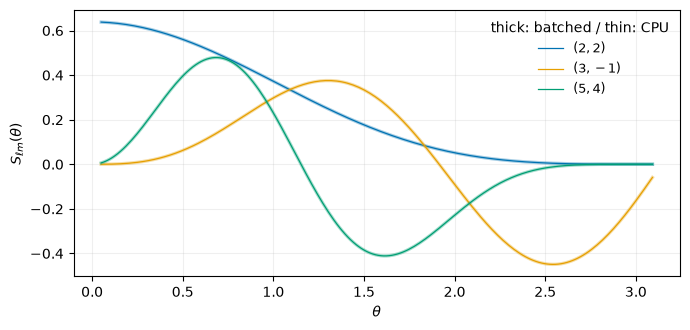

In [5]:
th = np.linspace(0.05, np.pi - 0.05, 200)
fig, ax = plt.subplots(figsize=(7, 3.4))
for color, (l, m) in zip(C, [(2, 2), (3, -1), (5, 4)]):
    i = cpu.mode_index(l, m, 0, 0)
    vals = np.asarray(swsh_theta_values(
        -2, np.array([m]), np.array([max(2, abs(m))]),
        cpu.coupling[i][None, :], th))[0]
    ref = SpinWeightedSpheroidalHarmonic(-2, l, m, orbit.a * cpu.frequencies[i])
    want = np.array([ref.eval(t) for t in th])
    assert np.max(np.abs(vals - want)) < 1e-9
    ax.plot(th, vals, lw=2.4, color=color, alpha=0.35)
    ax.plot(th, want, lw=0.9, color=color, label=rf"$({l},{m})$")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$S_{\ell m}(\theta)$")
ax.legend(frameon=False, fontsize=9, title="thick: batched / thin: CPU")
ax.grid(alpha=0.2)
plt.tight_layout()

rng = np.random.default_rng(0)
B = 6
amps = rng.normal(size=B) + 1j * rng.normal(size=B)
radial = rng.normal(size=(B, 4)) + 1j * rng.normal(size=(B, 4))
angular = rng.normal(size=(B, 3))
mm = np.array([2, 2, -1, 3, 1, -2]); om = rng.normal(size=B)
phi = np.array([0.0, 1.3]); t = 2.7
got = np.asarray(assemble_field(amps, radial, angular, mm, om, phi, t=t))
want = np.einsum("b,bs,bh,bp->shp", amps, radial, angular,
                 np.exp(1j * (mm[:, None] * phi[None, :] - om[:, None] * t)))
assert np.max(np.abs(got - want)) < 1e-12
print("assemble_field vs direct contraction: OK")

## Summary

1. batched circular grid ≡ CPU grid generator (amplitudes, eigenvalues,
   coupling, radial grids, harmonic container)
2. batched projection ≡ `cast_to_spherical`
3. batched $S(\theta)$ ≡ per-mode CPU class
4. summation einsums ≡ direct contraction

`pytest tests/ -q`: 45 tests.